<a href="https://colab.research.google.com/github/dayeon-yu/income-prediction-catboost/blob/main/code.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 소득 예측 (Income Prediction) — CatBoost 제출 파이프라인
**Pattern Recognition (02) · Team 16 · 2026-05-31 제출본** — 이 노트북 하나로 `prediction.csv`를 재현한다.

| 단계 | 내용 |
| --- | --- |
| 1 | 데이터 로드 (교수님 배포 `train.csv` / `test.csv`) |
| 2 | 클리닝 + Base Feature Engineering 6개 |
| 3 | KFold(5) Out-of-Fold Target Encoding 5개 — 누수 방지 |
| 4 | Group Aggregation 7개 — cross-row 통계 |
| 5–6 | Stratified holdout(80/20) · CatBoost 학습 (early stopping) |
| 7 | 평가식 `(F1+AUC)/2` 기준 Threshold 최적화 |
| 8 | 전체 train 재학습 → `prediction.csv` |
| 9 | 모델 해석 — CatBoost feature importance |

> 여러 모델 비교 · 피처 ablation · 검증 방식 점검 · 오류/공정성 분석은 [`notebooks/analysis.ipynb`](notebooks/analysis.ipynb)에 있다.
> 검증 결과(holdout): **AUC 0.9306 · F1 0.7373 · (F1+AUC)/2 = 0.8339**, threshold 0.422.


In [8]:
   !git clone https://github.com/dayeon-yu/income-prediction-catboost.git
   %cd income-prediction-catboost

Cloning into 'income-prediction-catboost'...
remote: Enumerating objects: 73, done.
remote: Counting objects: 100% (73/73), done.
remote: Compressing objects: 100% (69/69), done.
remote: Total 73 (delta 17), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (73/73), 2.03 MiB | 5.12 MiB/s, done.
Resolving deltas: 100% (17/17), done.
/content/income-prediction-catboost/income-prediction-catboost/income-prediction-catboost/income-prediction-catboost


In [9]:
# Colab 등 catboost가 없는 환경에서만 설치
try:
    import catboost  # noqa: F401
except ImportError:
    !pip install catboost --quiet


In [10]:
%cd /content/income-prediction-catboost
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, KFold
from sklearn.metrics import f1_score, roc_auc_score
from catboost import CatBoostClassifier

# 교수님 배포 파일은 CSV다. Colab/Drive를 쓰면 경로만 바꾸면 된다.
# 예) '/content/drive/MyDrive/Colab Notebooks/Pattern/train.csv'
TRAIN_PATH = 'data/train.csv'
TEST_PATH = 'data/test.csv'
RANDOM_STATE = 42

def read_table(path):
    """확장자로 CSV/XLSX를 구분해서 읽는다 (과제 배포본은 CSV, 팀 작업본은 XLSX였음)."""
    return pd.read_excel(path) if str(path).lower().endswith(('.xlsx', '.xls')) else pd.read_csv(path)

# 1. 데이터 로드
train_df = read_table(TRAIN_PATH)
test_df = read_table(TEST_PATH)

print('Train shape:', train_df.shape)   # (39073, 15)
print('Test shape:', test_df.shape)     # (9769, 14)


/content/income-prediction-catboost
Train shape: (39073, 15)
Test shape: (9769, 14)


## 2. Base Feature Engineering

In [11]:
def base_engineering(df):
    """클리닝 + Base FE 6개 (행 단위 stateless 변환 → train/test에 같은 함수 적용).

    결측 처리 원칙: 대체(mode)하지 않고 'Unknown' 카테고리로 **보존**한다.
    - 배포 데이터의 결측은 빈 칸(NaN)이고, 원본 UCI Adult는 '?'로 표기된다 → 둘 다 'Unknown'으로 통일
    - workclass 결측 집단의 >50K 비율은 9.1%(정상 24.8%)로, 결측 자체가 강한 음(-)의 신호
    - 주의: fillna를 astype(str)보다 먼저 해야 한다. pandas 2.x에서 NaN.astype(str)은 'nan' 문자열이 되어
      Unknown으로 합쳐지지 않는다 (제출 당시 코드의 순서 버그를 수정).
    """
    df = df.copy()
    for col in df.select_dtypes(include=['object', 'string']).columns:
        s = df[col].fillna('Unknown').astype(str).str.strip()
        df[col] = s.replace({'?': 'Unknown', '': 'Unknown', 'nan': 'Unknown'})

    # Base FE 6개 — 단순 변환이지만 상호작용(sex×marital, edu×occ)은 EDA에서 확인된 강한 조건부 패턴을 명시한다
    df['cap_net'] = df['capital_gain'] - df['capital_loss']
    df['has_capital_stats'] = ((df['capital_gain'] > 0) | (df['capital_loss'] > 0)).astype(int)
    df['gain_per_hour'] = df['capital_gain'] / (df['hours_per_week'] + 1)
    df['age_bins'] = pd.cut(
        df['age'], bins=[0, 25, 35, 45, 60, 100],
        labels=['Young', 'Junior', 'Senior', 'Veteran', 'Retired']
    ).astype(str)
    df['sex_marital'] = df['sex'] + '_' + df['marital_status']
    df['edu_occ'] = df['education'] + '_' + df['occupation']
    return df

y = (train_df['income'].astype(str).str.strip() == '>50K').astype(int)
test_ids = test_df['id']

X = base_engineering(train_df.drop(columns=['income', 'id']))
X_test = base_engineering(test_df.drop(columns=['id']))

print('Base FE 적용 후:', X.shape, '|', X_test.shape)
print('결측 → Unknown:', {c: int((X[c] == 'Unknown').sum()) for c in ['workclass', 'occupation', 'native_country']})


Base FE 적용 후: (39073, 19) | (9769, 19)
결측 → Unknown: {'workclass': 2213, 'occupation': 2223, 'native_country': 678}


## 3.Target Encoding (KFold OOF) — 누수 방지


In [12]:
def kfold_target_encode(train_series, target, test_series, n_splits=5, smoothing=10, random_state=42):
    """
    KFold target encoding (out-of-fold) — 누수 방지.

    Args:
        train_series: 범주형 train 값 (pd.Series)
        target: y_train (pd.Series)
        test_series: 범주형 test 값
        n_splits: KFold 수 (보통 5)
        smoothing: 적은 샘플 카테고리에 global mean 영향력 (높을수록 보수적)

    Returns:
        encoded_train, encoded_test
    """
    kf = KFold(n_splits=n_splits, shuffle=True, random_state=random_state)
    global_mean = target.mean()
    encoded_train = pd.Series(index=train_series.index, dtype=float)

    # Train: OOF 인코딩
    for train_idx, val_idx in kf.split(train_series):
        fold_train_x = train_series.iloc[train_idx]
        fold_train_y = target.iloc[train_idx]

        agg = fold_train_y.groupby(fold_train_x).agg(['mean', 'count'])
        # Smoothed mean: 적은 count의 카테고리는 global_mean으로 끌림
        smooth = (agg['mean'] * agg['count'] + global_mean * smoothing) / (agg['count'] + smoothing)

        encoded_train.iloc[val_idx] = train_series.iloc[val_idx].map(smooth).fillna(global_mean).values

    # Test: 전체 train으로 인코딩
    agg_full = target.groupby(train_series).agg(['mean', 'count'])
    smooth_full = (agg_full['mean'] * agg_full['count'] + global_mean * smoothing) / (agg_full['count'] + smoothing)
    encoded_test = test_series.map(smooth_full).fillna(global_mean)

    return encoded_train, encoded_test

# 고카디널리티 범주형에 target encoding 적용
te_cols = ['occupation', 'native_country', 'edu_occ', 'sex_marital', 'workclass']

for col in te_cols:
    enc_train, enc_test = kfold_target_encode(
        X[col], y, X_test[col],
        n_splits=5, smoothing=10, random_state=RANDOM_STATE
    )
    X[f'{col}_te'] = enc_train.values
    X_test[f'{col}_te'] = enc_test.values
    print(f'  {col}_te 추가됨 (train mean={enc_train.mean():.4f}, test mean={enc_test.mean():.4f})')

print(f'\nTarget Encoding 후: X={X.shape}, X_test={X_test.shape}')

  occupation_te 추가됨 (train mean=0.2393, test mean=0.2380)
  native_country_te 추가됨 (train mean=0.2395, test mean=0.2394)
  edu_occ_te 추가됨 (train mean=0.2414, test mean=0.2404)
  sex_marital_te 추가됨 (train mean=0.2395, test mean=0.2372)
  workclass_te 추가됨 (train mean=0.2390, test mean=0.2407)

Target Encoding 후: X=(39073, 24), X_test=(9769, 24)


## 4. Group Aggregation Features


In [13]:
def add_group_aggregations(train_df, test_df, group_col, num_cols):
    """
    그룹별 평균을 train_df, test_df에 새 컬럼으로 추가 (train 통계 기반).

    Args:
        train_df, test_df: 변환할 dataframe
        group_col: 그룹화 기준 (예: 'occupation')
        num_cols: 평균을 구할 수치형 컬럼들
    """
    # Train에서만 통계 계산
    group_stats = train_df.groupby(group_col)[num_cols].mean()

    for col in num_cols:
        new_col = f'{group_col}_mean_{col}'
        train_df[new_col] = train_df[group_col].map(group_stats[col])
        test_df[new_col] = test_df[group_col].map(group_stats[col])
        # test에 없는 카테고리 발생 시 train global mean으로 채움
        global_mean = train_df[col].mean()
        train_df[new_col] = train_df[new_col].fillna(global_mean)
        test_df[new_col] = test_df[new_col].fillna(global_mean)

    return train_df, test_df

# 적용
agg_specs = [
    ('occupation',     ['age', 'education_num', 'hours_per_week']),
    ('native_country', ['education_num', 'hours_per_week']),
    ('workclass',      ['age', 'hours_per_week']),
]

for group_col, num_cols in agg_specs:
    X, X_test = add_group_aggregations(X, X_test, group_col, num_cols)
    print(f'  {group_col}별 {num_cols} 평균 추가됨')

print(f'\nGroup Aggregation 후: X={X.shape}, X_test={X_test.shape}')
print(f'총 컬럼: {X.shape[1]}개')

  occupation별 ['age', 'education_num', 'hours_per_week'] 평균 추가됨
  native_country별 ['education_num', 'hours_per_week'] 평균 추가됨
  workclass별 ['age', 'hours_per_week'] 평균 추가됨

Group Aggregation 후: X=(39073, 31), X_test=(9769, 31)
총 컬럼: 31개


In [14]:
# 범주형 피처 자동 인식
cat_features = X.select_dtypes(include=['object', 'string']).columns.tolist()  # pandas 2.x(object)·3.x(str) 모두 대응
print('범주형 컬럼 수:', len(cat_features))
print('수치형 컬럼 수:', X.shape[1] - len(cat_features))
print('\n전체 컬럼:')
for c in X.columns:
    print(f'  {c} ({X[c].dtype})')

범주형 컬럼 수: 11
수치형 컬럼 수: 20

전체 컬럼:
  age (int64)
  workclass (object)
  education (object)
  education_num (int64)
  marital_status (object)
  occupation (object)
  relationship (object)
  race (object)
  sex (object)
  capital_gain (int64)
  capital_loss (int64)
  hours_per_week (int64)
  native_country (object)
  cap_net (int64)
  has_capital_stats (int64)
  gain_per_hour (float64)
  age_bins (object)
  sex_marital (object)
  edu_occ (object)
  occupation_te (float64)
  native_country_te (float64)
  edu_occ_te (float64)
  sex_marital_te (float64)
  workclass_te (float64)
  occupation_mean_age (float64)
  occupation_mean_education_num (float64)
  occupation_mean_hours_per_week (float64)
  native_country_mean_education_num (float64)
  native_country_mean_hours_per_week (float64)
  workclass_mean_age (float64)
  workclass_mean_hours_per_week (float64)


## 5. 데이터 분할 (단일 train/val split)

In [15]:
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)
print('Train:', X_train.shape, '| Val:', X_val.shape)

Train: (31258, 31) | Val: (7815, 31)


## 6. CatBoost 학습

In [16]:
model = CatBoostClassifier(
    iterations=2500,
    learning_rate=0.02,
    depth=7,
    l2_leaf_reg=10,
    bagging_temperature=0.8,
    random_strength=1,
    border_count=254,
    random_seed=RANDOM_STATE,
    cat_features=cat_features,
    early_stopping_rounds=200,
    verbose=200
)

model.fit(X_train, y_train, eval_set=(X_val, y_val), use_best_model=True)

0:	learn: 0.6713811	test: 0.6712731	best: 0.6712731 (0)	total: 201ms	remaining: 8m 21s
200:	learn: 0.2904514	test: 0.2903990	best: 0.2903990 (200)	total: 20s	remaining: 3m 48s
400:	learn: 0.2785880	test: 0.2833993	best: 0.2833993 (400)	total: 38.1s	remaining: 3m 19s
600:	learn: 0.2715912	test: 0.2800787	best: 0.2800787 (600)	total: 55.2s	remaining: 2m 54s
800:	learn: 0.2670277	test: 0.2781647	best: 0.2781647 (800)	total: 1m 12s	remaining: 2m 34s
1000:	learn: 0.2634293	test: 0.2772964	best: 0.2772876 (994)	total: 1m 31s	remaining: 2m 16s
1200:	learn: 0.2596640	test: 0.2766420	best: 0.2766262 (1188)	total: 1m 49s	remaining: 1m 58s
1400:	learn: 0.2565678	test: 0.2762718	best: 0.2762718 (1400)	total: 2m 6s	remaining: 1m 39s
1600:	learn: 0.2535299	test: 0.2757815	best: 0.2757807 (1599)	total: 2m 24s	remaining: 1m 21s
1800:	learn: 0.2507830	test: 0.2756149	best: 0.2756086 (1796)	total: 2m 42s	remaining: 1m 2s
2000:	learn: 0.2477165	test: 0.2754115	best: 0.2753601 (1966)	total: 3m	remaining: 

CatBoostClassifier(bagging_temperature=0.8, border_count=254, cat_features=['workclass', 'education', 'marital_status', 'occupation', 'relationship', 'race', 'sex', 'native_country', 'age_bins', 'sex_marital', 'edu_occ'], depth=7, early_stopping_rounds=200, iterations=2500, l2_leaf_reg=10, learning_rate=0.02, random_seed=42, random_strength=1, verbose=200)

## 7. Threshold 최적화

In [17]:
val_probs = model.predict_proba(X_val)[:, 1]
auc_score = roc_auc_score(y_val, val_probs)

# 평가식 (F1 + AUC) / 2 에서 AUC는 threshold와 무관하므로, threshold 최적화는 F1 최대화와 같다.
# 0.1~0.8을 0.001 간격(701개)으로 탐색한다. (analysis.ipynb 5.3절: F1은 0.27~0.46 구간에서 평평하다)
best_threshold = 0.5
best_metric = -1

for th in np.linspace(0.1, 0.8, 701):
    val_preds = (val_probs >= th).astype(int)
    f1 = f1_score(y_val, val_preds)
    current_metric = (f1 + auc_score) / 2
    if current_metric > best_metric:
        best_metric = current_metric
        best_threshold = th

print('\n' + '=' * 50)
print(f'최적 Threshold: {best_threshold:.4f}')
print(f'검증 AUC: {auc_score:.4f}')
print(f'검증 F1: {f1_score(y_val, (val_probs >= best_threshold).astype(int)):.4f}')
print(f'최종 Target ((F1+AUC)/2): {best_metric:.4f}')
print('=' * 50)



최적 Threshold: 0.4220
검증 AUC: 0.9306
검증 F1: 0.7373
최종 Target ((F1+AUC)/2): 0.8339


## 8. 전체 데이터 재학습 및 prediction.csv 저장

In [18]:
# holdout에서 early stopping이 고른 최적 반복 수로 전체 train을 다시 학습한다.
# (제출 당시 로그: bestIteration = 2498 / 2500 → 조기 종료가 사실상 발동하지 않았으므로
#  2500으로 재학습한 제출본과 거의 같은 모델이다. 더 많은 iteration이 도움이 될 여지가 있다는 뜻이기도 하다.)
best_iter = model.get_best_iteration() + 1
print(f'재학습 iterations = {best_iter}')

final_model = CatBoostClassifier(
    iterations=best_iter, learning_rate=0.02, depth=7,
    l2_leaf_reg=10, bagging_temperature=0.8, random_strength=1,
    border_count=254, random_seed=RANDOM_STATE,
    cat_features=cat_features, verbose=False
)
final_model.fit(X, y)

test_probs = final_model.predict_proba(X_test)[:, 1]
test_cls = (test_probs >= best_threshold).astype(int)

prediction_df = pd.DataFrame({
    'id': test_ids,
    'y_cls': test_cls,
    'y_prob': test_probs
})
prediction_df.to_csv('prediction.csv', index=False)

print('prediction.csv 생성 완료')
print('Test 예측 분포:')
print(prediction_df['y_cls'].value_counts())
print('\n샘플:')
print(prediction_df.head())


재학습 iterations = 2499
prediction.csv 생성 완료
Test 예측 분포:
y_cls
0    7474
1    2295
Name: count, dtype: int64

샘플:
      id  y_cls    y_prob
0   7763      0  0.002038
1  23882      0  0.216839
2  30508      0  0.069389
3  28912      1  0.989132
4  19485      0  0.000339


In [19]:
# (선택) Colab에서 결과 파일 내려받기
try:
    from google.colab import files
    files.download('prediction.csv')
except ImportError:
    pass


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 9. 모델 해석 — CatBoost feature importance

두 가지 중요도를 함께 본다.
- **PredictionValuesChange**: 피처 값이 바뀔 때 예측이 얼마나 변하는가 (기본 중요도)
- **LossFunctionChange**: 피처를 제거했을 때 검증 손실이 얼마나 나빠지는가 (holdout 기준, 더 보수적)

`notebooks/analysis.ipynb` 6절의 permutation importance와 순위를 비교하면 `capital_gain` · `edu_occ` · `age` · `sex_marital`이 공통 상위권이다.

                               PredictionValuesChange  LossFunctionChange
relationship                                  11.9528              0.0128
cap_net                                       11.3381              0.0085
hours_per_week                                 7.0026              0.0075
capital_gain                                   8.1981              0.0064
age                                            6.8775              0.0053
sex_marital                                    6.6561              0.0051
age_bins                                       6.4980              0.0043
capital_loss                                   3.5794              0.0033
education                                      4.2208              0.0028
sex_marital_te                                 6.0836              0.0025
marital_status                                 3.2316              0.0022
occupation_mean_education_num                  2.1215              0.0019
edu_occ_te                            

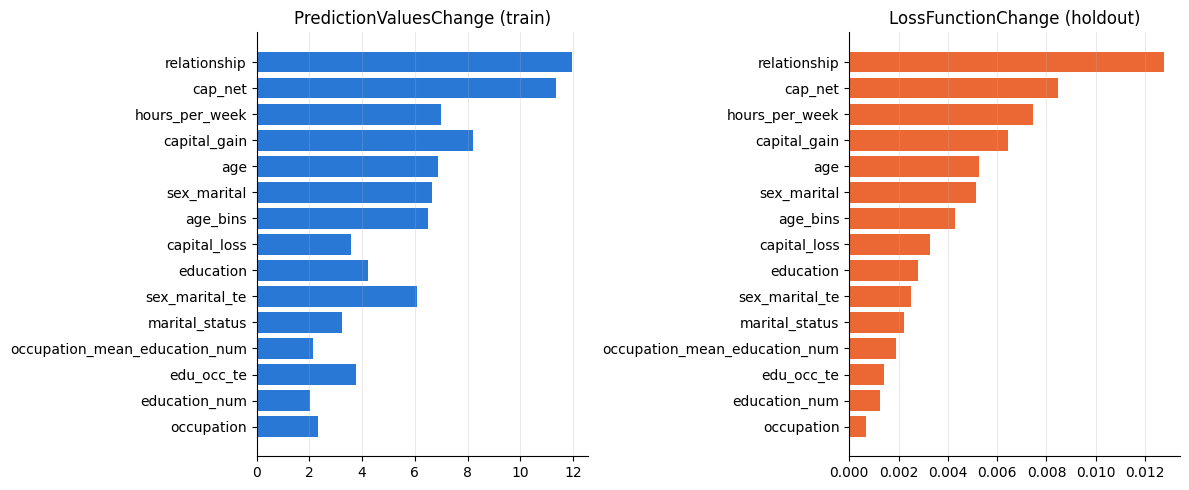

In [20]:
import matplotlib.pyplot as plt
from catboost import Pool

val_pool = Pool(X_val, y_val, cat_features=cat_features)
imp_pvc = pd.Series(model.get_feature_importance(type='PredictionValuesChange'), index=X_val.columns)
imp_lfc = pd.Series(model.get_feature_importance(val_pool, type='LossFunctionChange'), index=X_val.columns)
imp = pd.DataFrame({'PredictionValuesChange': imp_pvc, 'LossFunctionChange': imp_lfc}).sort_values('LossFunctionChange', ascending=False)
print(imp.head(15).round(4).to_string())

top = imp.head(15).iloc[::-1]
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
ax[0].barh(top.index, top['PredictionValuesChange'], color='#2a78d6'); ax[0].set_title('PredictionValuesChange (train)')
ax[1].barh(top.index, top['LossFunctionChange'], color='#eb6834'); ax[1].set_title('LossFunctionChange (holdout)')
for a in ax:
    a.spines['top'].set_visible(False); a.spines['right'].set_visible(False); a.grid(axis='x', alpha=0.25)
plt.tight_layout(); plt.show()


## 10. 재현 안내

- 실행 환경: Python 3.10+, `pip install -r requirements.txt`
- `data/train.csv`, `data/test.csv`를 두고 위에서부터 실행하면 약 6분(CPU) 뒤 `prediction.csv`가 생성된다.
- 저장소의 `prediction.csv`는 2026-05-31 제출본이다. CatBoost CPU 학습은 버전·스레드 수에 따라 마지막 자리에서 미세하게 달라질 수 있다.